<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.2 – Word and sentence embeddings

**Objectives**
- Train Word2Vec embeddings (CBOW and Skip-gram) on your own corpus
- Use pre-trained GloVe vectors and word analogies
- Compute sentence embeddings with a BERT-based model and use them for semantic search
- Compare lexical (TF-IDF) and semantic (embeddings) similarity

**Dataset:** the same 20 Newsgroups corpus and the same 3 categories as in Lab 3.1.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. This lab downloads pre-trained models (about 250 MB in total). Google Colab is recommended on a slow connection.

## Setup

In [5]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
!pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [6]:
import os, re, string, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import gensim
from gensim.models import Word2Vec
import gensim.downloader as api
from sklearn.metrics.pairwise import cosine_similarity

print(f"gensim {gensim.__version__} – setup complete")

gensim 4.4.0 – setup complete


## Data (same as Lab 3.1)

In [8]:
def local_file(name, lab="lab3"):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))
df = df.dropna(subset=["text"]).reset_index(drop=True)

my_categories = [
    "rec.autos",
    "rec.sport.hockey",
    "sci.crypt"
]
assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Use 3 valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"{len(df_filtered)} documents in {my_categories}")

1789 documents in ['rec.autos', 'rec.sport.hockey', 'sci.crypt']


In [9]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_tokens(text):
    """Same cleaning as Lab 3.1, returning a list of tokens (Word2Vec expects tokenized sentences)."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words and len(t) >= 3]
    return tokens

df_filtered["tokens"] = df_filtered["text"].apply(preprocess_tokens)
df_filtered["text_clean"] = df_filtered["tokens"].apply(" ".join)
corpus = df_filtered["tokens"].tolist()
print(f"Corpus: {len(corpus)} documents, {sum(len(d) for d in corpus)} tokens")
print(corpus[0][:15])

Corpus: 1789 documents, 175201 tokens
['wondering', 'anyone', 'could', 'enlighten', 'car', 'saw', 'day', 'door', 'sport', 'car', 'looked', 'late', 'early', 'called', 'bricklin']


---
# Part A – Word2Vec: train your own embeddings

Word2Vec learns a vector per word by predicting words from their context:
- **CBOW** predicts the target word from its context words,
- **Skip-gram** predicts the context words from the target word.

In [10]:
common = dict(sentences=corpus, vector_size=100, window=5, min_count=5, workers=4, epochs=10, seed=42)
model_cbow = Word2Vec(sg=0, **common)
model_skipgram = Word2Vec(sg=1, **common)
print(f"Vocabulary size: {len(model_cbow.wv)} words")

Vocabulary size: 4998 words


In [11]:
word = "game"   # change to a word of your domain
if word in model_cbow.wv:
    print(f"Vector of '{word}': shape {model_cbow.wv[word].shape}, first values {model_cbow.wv[word][:5]}")
    print("\nMost similar (CBOW):     ", [w for w, s in model_cbow.wv.most_similar(word, topn=8)])
    print("Most similar (Skip-gram):", [w for w, s in model_skipgram.wv.most_similar(word, topn=8)])
else:
    print(f"'{word}' is not in the vocabulary. Examples:", list(model_cbow.wv.key_to_index)[:20])

Vector of 'game': shape (100,), first values [ 0.9962863   0.62072915  0.7755096  -0.9147069  -0.40200287]

Most similar (CBOW):      ['played', 'season', 'playoff', 'pick', 'playing', 'cup', 'team', 'night']
Most similar (Skip-gram): ['playoff', 'played', 'winning', 'streak', 'espn', 'television', 'seven', 'gld']


### Exercise A.1 – CBOW vs Skip-gram

Choose **5 domain-specific words** of your categories (not generic words such as *good* or *make*) and compare the 5 most similar words given by each model.

In [12]:
my_test_words = [
    "hockey",
    "puck",
    "goalie",
    "engine",
    "encryption"
]

for word in my_test_words:
    word = word.lower()
    if word in model_cbow.wv:
        print(f"\n'{word}'")
        print("  CBOW:     ", [w for w, s in model_cbow.wv.most_similar(word, topn=5)])
        print("  Skip-gram:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)])
    else:
        print(f"\n'{word}' not in vocabulary")
assert sum(w.lower() in model_cbow.wv for w in my_test_words) >= 3, "At least 3 of your words must be in the vocabulary"


'hockey'
  CBOW:      ['nhl', 'league', 'canadian', 'sport', 'stats']
  Skip-gram: ['canadian', 'pro', 'nhl', 'league', 'college']

'puck'
  CBOW:      ['flyer', 'soderstrom', 'sabre', 'shot', 'penalty']
  Skip-gram: ['circle', 'slot', 'rebound', 'across', 'slid']

'goalie'
  CBOW:      ['roussel', 'cap', 'tonight', 'ice', 'shark']
  Skip-gram: ['ketterer', 'finishing', 'shutout', 'skater', 'defensemen']

'engine'
  CBOW:      ['oil', 'tire', 'drive', 'quite', 'price']
  Skip-gram: ['trunk', 'valve', 'diesel', 'liter', 'gasoline']

'encryption'
  CBOW:      ['voice', 'product', 'classified', 'device', 'transmits']
  Skip-gram: ['possibility', 'dual', 'attached', 'sword', 'ordinary']


### Question A.2 (written)

1. For which words do both models agree? For which do they differ?
2. Which model gives the better neighbours for your domain? Give examples.
3. Why can one architecture work better than the other for rare words? (think about how many training examples each word gets)

<!-- ANSWER lab3.2-A2 -->
**Your answer:**

*(1. for hockey there is one agreement, both models show "canadian". but its mostly differes for "puck", "goalie" and "encryption". for "engine", both models show auto related words, but they are different.
2. i think both models did great, but CBOW is a bit better for my categories. for example for "engine" it showed more words clearly related to engine, as for Skip-gram it showed a bit less.
3. Skip-gram learns by predicting surrounding words from each targer word and SBOW oredicts a target word from its surroundings context, so i think SBOW can make learning less effective for rare words especialy   )*
<!-- END ANSWER -->

### Exercise A.3 – Analogies with your model

In [13]:
def analogy(model, a, b, c, topn=3):
    """a is to b as c is to ?   (vector arithmetic: b - a + c)"""
    try:
        return model.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
    except KeyError as e:
        return f"Word not in vocabulary: {e}"

# Try 2 analogies built from words of YOUR vocabulary
print(analogy(model_skipgram, "car", "engine", "hockey"))
print(analogy(model_skipgram, "hockey", "puck", "goalie"))

[('canadian', 0.516075611114502), ('pro', 0.5139509439468384), ('alex', 0.4998010993003845)]
[('slot', 0.8242486715316772), ('rebound', 0.820673942565918), ('circle', 0.7929835319519043)]


### Question A.4 (written)

Did the analogies work? If yes, why does the result make sense; if not, what explains the failure (corpus size, vocabulary, frequency)?

<!-- ANSWER lab3.2-A4 -->
**Your answer:**

*(the first analogy definetely failed. the model didnt identify a clear relationship between cars and hockey. the second one understands teh general context, but it didnt produce one clearly correct answer. i think it can be explained by small training corpus size, limited vocanulary and difference in word frequency.)*
<!-- END ANSWER -->

---
# Part B – Pre-trained GloVe embeddings

GloVe vectors trained on Wikipedia + Gigaword (6 billion tokens, 400 000 words, 100 dimensions). The download (about 130 MB) is cached by gensim.

In [14]:
print("Loading GloVe (first time: about 1 minute)...")
glove_model = api.load("glove-wiki-gigaword-100")
print(f"GloVe loaded: {len(glove_model.key_to_index)} words")

Loading GloVe (first time: about 1 minute)...
[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe loaded: 400000 words


### Exercise B.1 – Your model vs GloVe

In [15]:
comparison_words = ["hockey", "puck", "goalie"]

for word in comparison_words:
    word = word.lower()
    print(f"\n{'=' * 50}\n'{word}'")
    print("  Your Word2Vec:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)] if word in model_skipgram.wv else "not in vocabulary")
    print("  GloVe:        ", [w for w, s in glove_model.most_similar(word, topn=5)] if word in glove_model else "not in vocabulary")


'hockey'
  Your Word2Vec: ['canadian', 'pro', 'nhl', 'league', 'college']
  GloVe:         ['basketball', 'football', 'nhl', 'soccer', 'baseball']

'puck'
  Your Word2Vec: ['circle', 'slot', 'rebound', 'across', 'slid']
  GloVe:         ['crease', 'ball', 'deflected', 'skated', 'goalie']

'goalie'
  Your Word2Vec: ['ketterer', 'finishing', 'shutout', 'skater', 'defensemen']
  GloVe:         ['goaltender', 'netminder', 'brodeur', 'defenseman', 'belfour']


### Question B.2 (written)

1. For which words is your model more relevant than GloVe? Why?
2. For which words is GloVe better? Why?
3. In a real project, when would you train your own embeddings rather than use pre-trained ones?

<!-- ANSWER lab3.2-B2 -->
**Your answer:**

*(1. my model understands the hockey context better. glove associates hockey with general sports.
2. however, glove works better for "puck" and "goalie". it identifues relevant hockey terms such as crease, goaltender and netminder. its because glove was trained in a really large dataset.
3. i would use my own embeddings when working with a specialaised and specific reminology, as an example above it might be hockey.)*
<!-- END ANSWER -->

### Exercise B.3 – Analogies with GloVe

In [16]:
print("king - man + woman =", glove_model.most_similar(positive=["king", "woman"], negative=["man"], topn=3))

# Analogy 1: hockey equipment
print("puck - hockey + football =",
      glove_model.most_similar(
          positive=["puck", "football"],
          negative=["hockey"],
          topn=3
      ))

# Analogy 2: hockey positions
print("goalie - hockey + football =",
      glove_model.most_similar(
          positive=["goalie", "football"],
          negative=["hockey"],
          topn=3
      ))

# Analogy 3: sports
print("hockey - ice + basketball =",
      glove_model.most_similar(
          positive=["hockey", "basketball"],
          negative=["ice"],
          topn=3
      ))

king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]
puck - hockey + football = [('ball', 0.735937774181366), ('deflected', 0.6591001749038696), ('pass', 0.6471648216247559)]
goalie - hockey + football = [('goalkeeper', 0.7624865174293518), ('goaltender', 0.7041136026382446), ('defender', 0.6504042744636536)]
hockey - ice + basketball = [('football', 0.7561717629432678), ('soccer', 0.6970375776290894), ('baseball', 0.6719861626625061)]


---
# Part C – Sentence embeddings with a BERT-based model

`all-MiniLM-L6-v2` is a small transformer that maps a sentence (or a short document) to a 384-dimensional vector. Two texts with a similar meaning get close vectors, even without common words.

In [17]:
from sentence_transformers import SentenceTransformer
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

sample_sentences = [
    "I love programming in Python.",
    "Python is my favorite programming language.",
    "The python snake is very long.",
    "I enjoy coding and software development.",
]
embeddings = sentence_model.encode(sample_sentences)
print(f"Embeddings shape: {embeddings.shape}")

sim = cosine_similarity(embeddings)
pd.DataFrame(sim, index=[f"S{i}" for i in range(4)], columns=[f"S{i}" for i in range(4)]).round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings shape: (4, 384)


,S0,S1,S2,S3
S0,1.000,0.878,0.370,0.621
S1,0.878,1.000,0.337,0.512
S2,0.370,0.337,1.000,0.058
S3,0.621,0.512,0.058,1.000


### Exercise C.1 – Document similarity with sentence embeddings

Encode 30 documents (10 per category, first 500 characters) and compute their cosine similarity matrix.

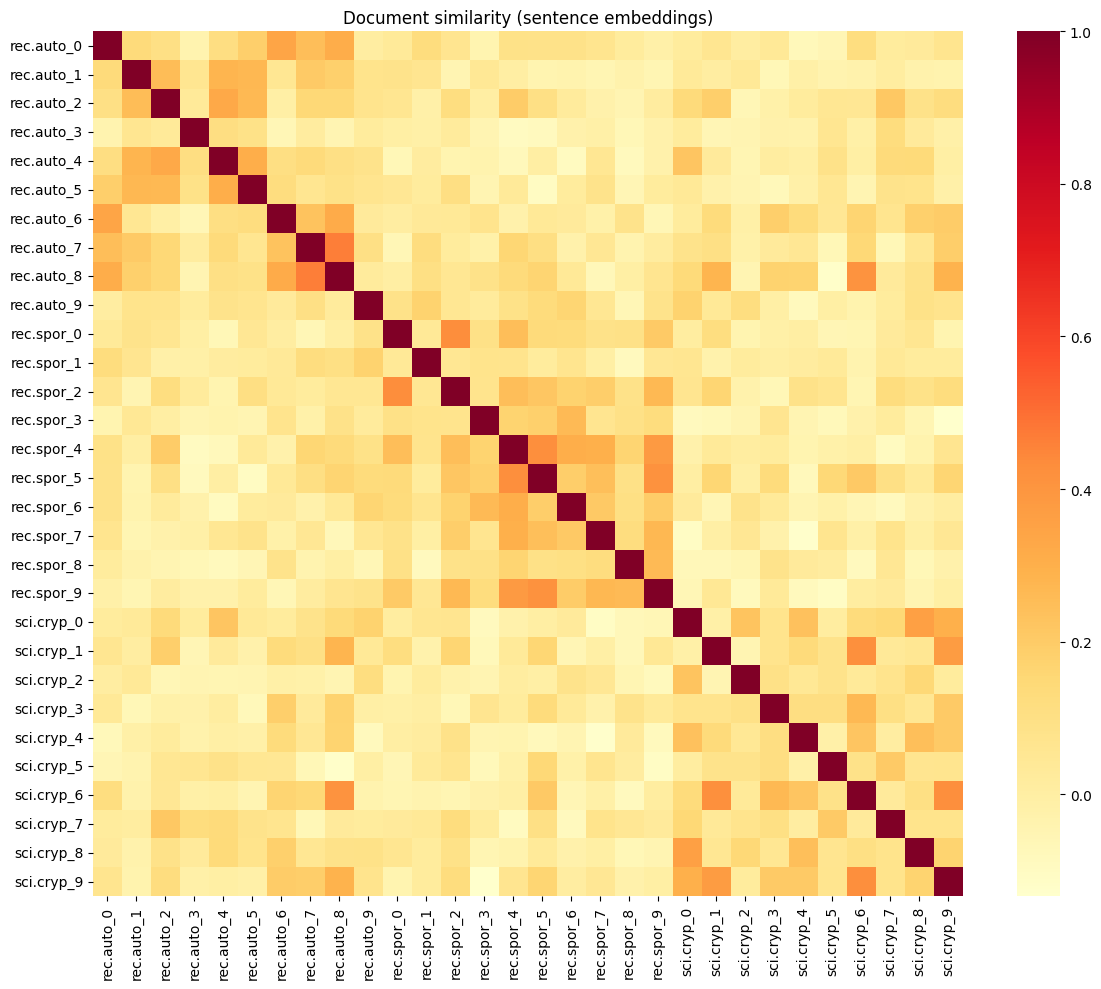

In [18]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
sampled_docs = df_sampled["text"].str[:500].tolist()
sampled_labels = df_sampled["label_text"].tolist()

doc_embeddings = sentence_model.encode(sampled_docs)
bert_similarity = cosine_similarity(doc_embeddings)

assert doc_embeddings.shape == (30, 384) and bert_similarity.shape == (30, 30)
labels = [f"{l[:8]}_{i % 10}" for i, l in enumerate(sampled_labels)]
plt.figure(figsize=(12, 10))
sns.heatmap(bert_similarity, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (sentence embeddings)")
plt.tight_layout()
plt.show()

### Question C.2 (written)

Compare with the TF-IDF heatmap of Lab 3.1 (same 30 documents):
1. Which representation groups documents of the same category better?
2. Are there documents judged similar by one method and not by the other? Why?
3. Which representation would you use for document classification? Why?

<!-- ANSWER lab3.2-C2 -->
**Your answer:**

*(1 sentence embeddings show clear grouping for documents. but, its less consistent from sports and cryptography from what i see on the heatmap. TF-IDF focuses on shared words, while sentence embeddings also capture sematic meaning.
2. yes. TF-IDF may show documents similar because they contain same keywords, but setnetce embeddings can identify documents with similar meanings even though they maybe use different words. so that means that two methods can produce similarity scores.
3. i would definetely use sentence embeddings because they capture semantic meaning and context rather than relying only on similar keywords. so it should make easier to analyze documents that have same topic. )*
<!-- END ANSWER -->

### Exercise C.3 – Semantic search

In [20]:
def semantic_search(query, documents, doc_embeddings, model, top_k=5):
    """Return the top_k (index, score) pairs of the documents closest to the query."""
    # 1. Encode the query
    query_embedding = model.encode([query])

    # 2. Calculate cosine similarity with every document
    similarities = cosine_similarity(query_embedding, doc_embeddings)[0]

    # 3. Get indices of the top_k highest scores
    top_indices = np.argsort(similarities)[::-1][:top_k]

    return [(int(i), float(similarities[i])) for i in top_indices]


# Search query related to automobiles
my_query = "Computer security, encryption and protecting personal information"

results = semantic_search(my_query, sampled_docs, doc_embeddings, sentence_model, top_k=5)

results = semantic_search(my_query, sampled_docs, doc_embeddings, sentence_model, top_k=5)
assert len(results) == 5 and all(0 <= i < 30 for i, _ in results)
print(f"Query: '{my_query}'")
for idx, score in results:
    print(f"\n  score {score:.3f} | {sampled_labels[idx]}")
    print("  " + sampled_docs[idx][:150].replace("\n", " "))

Query: 'Computer security, encryption and protecting personal information'

  score 0.232 | sci.crypt
   The average amerikan today seems to think that the government should be able to eavesdrop on everyone (else).  Opinion polls show that most people be

  score 0.221 | sci.crypt
  : It occurs to me that if they get a wiretap order on you, and the escrow : houses release your code to the cops, your code is now no longer secure. :

  score 0.211 | sci.crypt
  Gee, I guess they should also have such a repository for house keys, car keys, safety deposit keys, ... :-(  rdl

  score 0.208 | sci.crypt
  The system, or 'family', key would appear to be cryptographically useless, since *every* chip must know it and be able to remove its effects from the 

  score 0.206 | sci.crypt
     Once it hits land you can record it if you have telco access.  The    telco isn't supposed to give that without a warrant.  That's the rule today. 


### Question C.4 (written)

1. Are the results relevant to the query?
2. Do they come from the expected category?
3. Try a query that could match two of your categories: what happens?

<!-- ANSWER lab3.2-C4 -->
**Your answer:**

*(1. Most results are relevant to the query because they discuss cars etc. but the first result is least relevant because it started discussing encryption and keys, which is definetely not about cars.
2. most results come from expected category, yes. expect for the fist one as i mentioned above, i think it shows that sometimes semantix search can get documents from unreleveant categories.
3.  i tryed and pasted query about computer security, encryption and protecting personal information. all results ca,e from scu.crypt.that means the model identified the cryptography a bit better then about cars. however it didnt retieve documents from second category )*
<!-- END ANSWER -->

---
# Part D – Visualizing embeddings with t-SNE

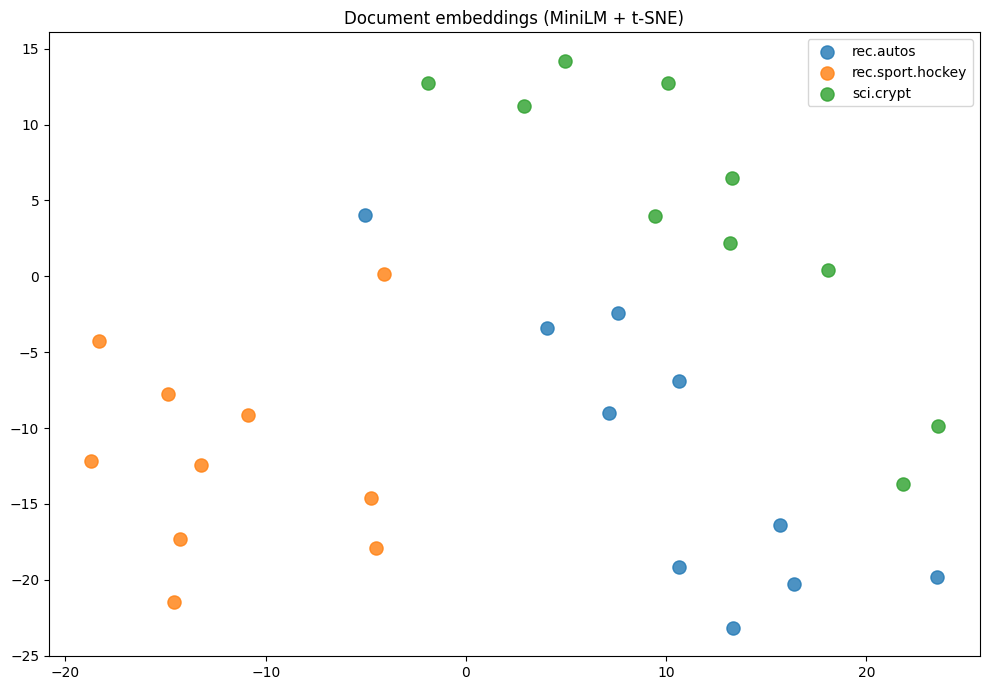

In [21]:
from sklearn.manifold import TSNE

embeddings_2d = TSNE(n_components=2, random_state=42, perplexity=10).fit_transform(doc_embeddings)
plt.figure(figsize=(10, 7))
for category in my_categories:
    mask = np.array(sampled_labels) == category
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], label=category, s=90, alpha=0.8)
plt.legend()
plt.title("Document embeddings (MiniLM + t-SNE)")
plt.tight_layout()
plt.show()

### Question D.1 (written)

1. Do the categories form distinct clusters?
2. Are there documents in the "wrong" cluster? What could explain it?
3. Which two categories are the closest? Does it match Lab 3.1?

<!-- ANSWER lab3.2-D1 -->
**Your answer:**

*(1. Pretty much yes. except for one blue dot above yellow one, meanwile majority of the are in the lower part.
2.yes, as i mentioned above.i think this might happen because some documents contain similar words or discuss topics that overlap with other documents.
3. auto and cryptography appear to be closest categories because some of their points are close together.its also consistent with TF-IDF heatmap from lab 3.1, even though two methods represent document similarity differently.)*
<!-- END ANSWER -->

---
# Part E – Final comparison

### Question E.1 (written)

1. Fill in the table.

| Method | Strengths | Weaknesses | Best use case |
|--------|-----------|------------|---------------|
| BoW|simple, counts word frequency  |ignores context and word order |basic text analysis
| TF-IDF |highlights important words|cant understand meaning |keyword-based classification |
| Word2Vec (own corpus)  |learns domain-specific word relationships|needs sufficient training data |domain-specific word analysis |
| GloVe |has large vocabulary, captures general word relationships |less effective with specialaised terminology |general word similarity |
| Sentence embeddings (MiniLM)  |runderstands context and semantic meaning|requures more computational resources |semantic search and document classification |

2. For your categories, which method worked best overall? Support the answer with results from Labs 3.1 and 3.2.
3. For a real classification system on these categories, which representation would you choose and why?

<!-- ANSWER lab3.2-E1 -->
**Your answer:**

*(2.I liked how Sentence embeddings worked for my categories. in lab 3.2 the t-SNE visualisation showed distinct clusters for auto, sports and cryptography. the model also identified relevant documents during semantic search, even when it didnt show exactly the same keywords.
3. i would choose sentence embeddings because they capture the meaning and context of documents. so this allows the system to classify texts even when they use different words to describe similar topics.  it would be really useful for documents with different categories and overlapping vocabulary)*
<!-- END ANSWER -->

---
## Summary

- Word2Vec learns word vectors from your corpus; CBOW and Skip-gram differ in what they predict.
- Pre-trained vectors (GloVe) cover a large general vocabulary and support analogies.
- Sentence-transformer models embed whole texts and enable semantic search without shared words.
- t-SNE projects embeddings in 2-D to inspect how documents group together.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.